In [ ]:
# Installs
import importlib.metadata as md
if "+cu126" not in md.version("torch"):
    !pip uninstall -y torch torchvision
    !pip install torch==2.11.0 torchvision==0.26.0 --index-url https://download.pytorch.org/whl/cu126

!pip install pylidc
!test -d /content/pyradiomics_src || git clone -q https://github.com/AIM-Harvard/pyradiomics.git /content/pyradiomics_src
!pip install /content/pyradiomics_src
!pip install SimpleITK pydicom opencv-python --quiet
!pip install MLstatkit==0.1.91

Found existing installation: torch 2.11.0+cu130
Uninstalling torch-2.11.0+cu130:
  Successfully uninstalled torch-2.11.0+cu130
Found existing installation: torchvision 0.26.0+cu130
Uninstalling torchvision-0.26.0+cu130:
  Successfully uninstalled torchvision-0.26.0+cu130
Looking in indexes: https://download.pytorch.org/whl/cu126
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.2/287.2 MB 85.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.8/296.8 MB 79.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.1/139.1 MB 114.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 66.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 170.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 MB 78.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 195.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━

In [ ]:
# Imports

# Compatibility for pylidc
import configparser
if not hasattr(configparser, 'SafeConfigParser'):
    configparser.SafeConfigParser = configparser.ConfigParser
import numpy as np
np.int = int

# Standard library
import copy, gc, itertools, json, os, pickle, random, shutil
from itertools import combinations

# Mask connectivity, resampling and DeLong's test
import pandas as pd
import psutil
from scipy.ndimage import label as cc_label, zoom
from MLstatkit import Delong_test

# LIDC-IDRI and radiomics
import pylidc as pl
from pylidc.utils import consensus
import SimpleITK as sitk
from radiomics import featureextractor

# Deep learning
import torch
assert torch.__version__ == "2.11.0+cu126", "Wrong PyTorch build: restart the session"
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

# Feature reduction, classification and metrics
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, auc as sk_auc)

# Plotting
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/dist-packages/pylidc/__init__.py:27: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pr


In [ ]:
import sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
BASE = "/content/drive/MyDrive/LIDC-IDRI COLAB"

PREP_DIR         = f"{BASE}/preprocessed"
RESULTS_DIR      = f"{BASE}/results"
COMPARISON_DIR   = f"{RESULTS_DIR}/hu_clamp_resampling_comparison"
DATASET_DIR      = f"{BASE}/Dataset"
MANIFEST_PATH    = f"{BASE}/final_dataset_manifest.csv"
FOLD_SPLITS_PATH = f"{BASE}/fold_splits.pkl"

# Check folder
for p in [PREP_DIR, RESULTS_DIR, MANIFEST_PATH, FOLD_SPLITS_PATH]:
    print(("OK       " if os.path.exists(p) else "MISSING  ") + p)

OK       /content/drive/MyDrive/LIDC-IDRI COLAB/preprocessed
OK       /content/drive/MyDrive/LIDC-IDRI COLAB/results
OK       /content/drive/MyDrive/LIDC-IDRI COLAB/final_dataset_manifest.csv
OK       /content/drive/MyDrive/LIDC-IDRI COLAB/fold_splits.pkl


In [ ]:
# Checks whether the full preprocessed dataset already exists on drive
TARGET_N = 400
os.makedirs(PREP_DIR, exist_ok=True)

mask_files = [f for f in os.listdir(PREP_DIR) if f.endswith("_mask_c23.npy")]
complete_pids = [
    f.replace("_mask_c23.npy", "") for f in mask_files
    if f"{f.replace('_mask_c23.npy', '')}_raw_c1.npy" in os.listdir(PREP_DIR)
    and f"{f.replace('_mask_c23.npy', '')}_resampled_clamped_c23.npy" in os.listdir(PREP_DIR)
]

PREPROCESSING_ALREADY_DONE = len(complete_pids) >= TARGET_N

if PREPROCESSING_ALREADY_DONE:
    print(f"Found {len(complete_pids)} fully preprocessed patients in {PREP_DIR}.")
    print("Data preparation and preprocessing stage already complete.")
else:
    print(f"Found {len(complete_pids)}/{TARGET_N} preprocessed - running data preparation and preprocessing from scratch.")

Found 400 fully preprocessed patients in /content/drive/MyDrive/LIDC-IDRI COLAB/preprocessed.
Data preparation and preprocessing stage already complete.


In [ ]:
# Nodule grouping, exclusion and malignancy labels
scans = pl.query(pl.Scan).all() # Load all LIDC-IDRI scan records from pylidc's annotation database
print(f"{len(scans)} scans loaded")

dataset = []

benign_count = 0
malignant_count = 0
excluded_count = 0
excluded_too_many_annotators = 0

for scan in scans:
  try:
    nodules = scan.cluster_annotations()

    for nodule in nodules:

        # discard if > 4 annotators - pylidc likely merged two distinct nodules (Brocki & Chung)
        if len(nodule) > 4:
            excluded_too_many_annotators += 1
            continue

        ann = nodule[0]

        # diameter filter
        if ann.diameter < 3:
            continue

        scores = [a.malignancy for a in nodule]

        rounded_mean = round(np.mean(scores))  # Causey et al. (NoduleX): mean score rounded to nearest int

        # label assignment
        if rounded_mean in (1, 2): # S1/S2 -> benign
            label = 0
            benign_count += 1

        elif rounded_mean in (4, 5):  # S4/S5 -> malignant
            label = 1
            malignant_count += 1

        else:  # S3 excluded
            excluded_count += 1
            continue

        dataset.append({
            "patient_id": scan.patient_id,
            "label": label,
            "diameter": ann.diameter,
            "rounded_mean_score": rounded_mean,
            "scan": scan,
            "ann": ann,
            "anns": nodule, # full annotator list, needed for consensus masking later
        })
  except Exception as e:
        print(f"Error processing {scan.patient_id}: {e}")

print(f"Total usable: {len(dataset)}, benign: {benign_count}, malignant: {malignant_count}")
print(f"Excluded (score==3): {excluded_count}")
print(f"Excluded (>4 annotators, likely merged nodules): {excluded_too_many_annotators}")

1018 scans loaded
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 Annotations.
Some nodules may be close and must be grouped manually.
Failed to reduce all groups to <= 4 A

In [ ]:
# Dataset summary
print("\nResults")
print(f"Benign nodules: {benign_count}")
print(f"Malignant nodules: {malignant_count}")
print(f"Excluded nodules: {excluded_count}")
print(f"Total usable nodules: {benign_count + malignant_count}")
print("Number of patients:", len(set(item["patient_id"] for item in dataset)))


Results
Benign nodules: 1117
Malignant nodules: 494
Excluded nodules: 1021
Total usable nodules: 1611
Number of patients: 716


In [ ]:
# Minimum ROI-Filtering (largest consensus slice >= 7 mm^2)

# very small ROIs give too little information for stable feature extraction (Demircioglu, 2023)
MIN_AREA_MM2 = 7.0  # ~50 px threshold of Demircioglu (2023), applied as real area

filtered_dataset = []
excluded_too_small_count = 0

# removes nodules whose largest segmented slice is too small
for entry in dataset:
    scan = entry["scan"]
    anns = entry["anns"]

    try:
        cmask, cbbox, _ = consensus(anns, clevel=0.5, pad=5)  # 50% consensus mask (Tang et al.; Causey et al.)
        slice_areas = cmask.sum(axis=(0, 1))
        max_area_idx = int(np.argmax(slice_areas))   # largest slice, not an edge slice
        max_slice_pixel_count = int(slice_areas[max_area_idx])
        pixel_spacing = scan.pixel_spacing
        max_slice_area_mm2 = max_slice_pixel_count * (pixel_spacing ** 2)  # mm^2 using each scan's own spacing

        if max_slice_area_mm2 < MIN_AREA_MM2:
            excluded_too_small_count += 1
            continue

        entry["max_slice_area_mm2"] = round(max_slice_area_mm2, 2)
        filtered_dataset.append(entry)

    except Exception as e:
        print(f"  Consensus check failed for {entry['patient_id']}: {e}")
        excluded_too_small_count += 1

benign_count = sum(1 for e in filtered_dataset if e["label"] == 0)
malignant_count = sum(1 for e in filtered_dataset if e["label"] == 1)
dataset = filtered_dataset

print(f"Excluded for being too small (<{MIN_AREA_MM2} mm² in max-area slice): {excluded_too_small_count}")
print(f"Total usable after size filter: {len(dataset)}, benign: {benign_count}, malignant: {malignant_count}")

Excluded for being too small (<7.0 mm² in max-area slice): 42
Total usable after size filter: 1569, benign: 1076, malignant: 493


In [ ]:
# Disconnected-mask filter (26-connectivity)
# skipped if preprocessing is already complete
if not PREPROCESSING_ALREADY_DONE:
    structure_full = np.ones((3, 3, 3))  # 26-connectivity counts face, edge, and corner touches as connected (Borgefors
                                      # et al., 1997), catching cases a stricter rule would miss

    filtered_dataset_v2 = []
    excluded_disconnected_count = 0

    for entry in dataset:
        anns = entry["anns"]
        try:
            cmask, cbbox, _ = consensus(anns, clevel=0.5, pad=5)
            _, n_components = cc_label(cmask, structure=structure_full)

            if n_components > 1:
                excluded_disconnected_count += 1
                continue

            filtered_dataset_v2.append(entry)
        except Exception as e: # consensus failure excludes the nodule
            print(f"  Connectivity check failed for {entry['patient_id']}: {e}")
            excluded_disconnected_count += 1

    dataset = filtered_dataset_v2
    print(f"Excluded for genuine mask disconnection (26-connectivity): {excluded_disconnected_count}")
    print(f"Pool size after disconnection filter: {len(dataset)}")
else:
    print("Preprocessing already complete, skipping disconnection filter.")

Preprocessing already complete, skipping disconnection filter.


In [ ]:
# Balanced ceiling check
CEILING_PATH = f"{RESULTS_DIR}/balanced_ceiling.json"

if os.path.exists(CEILING_PATH):
    with open(CEILING_PATH) as f:
        ceiling_info = json.load(f)
    print("Balanced ceiling loaded from disk.")
else:
    print("Computing balanced ceiling (applies the connectivity filter)...")
    structure_full = np.ones((3, 3, 3))
    rows = []
    for entry in dataset:
        try:
            cmask, _, _ = consensus(entry["anns"], clevel=0.5, pad=5)
            if cc_label(cmask, structure=structure_full)[1] == 1:
                rows.append({"patient_id": entry["patient_id"], "label": int(entry["label"])})
        except Exception:
            pass
    pool = pd.DataFrame(rows)

    # a patient can contribute to either class but only once, so the ceiling is bounded by
    # both class-specific patient counts and by half the number of unique patients
    M = pool.loc[pool.label == 1, "patient_id"].nunique()
    B = pool.loc[pool.label == 0, "patient_id"].nunique()
    U = pool["patient_id"].nunique()

    ceiling_info = {
        "pool_nodules": len(pool),
        "pool_benign": int((pool["label"] == 0).sum()),
        "pool_malignant": int((pool["label"] == 1).sum()),
        "patients_with_benign": int(B),
        "patients_with_malignant": int(M),
        "patients_with_both": int(M + B - U),
        "unique_patients": int(U),
        "balanced_ceiling": int(2 * min(M, B, U // 2)),
    }

    with open(CEILING_PATH, "w") as f:
        json.dump(ceiling_info, f, indent=2)
    print("Balanced ceiling computed and saved.")

for k, v in ceiling_info.items():
    print(f"  {k:24} {v}")

Computing balanced ceiling (applies the connectivity filter)...
Balanced ceiling computed and saved.
  pool_nodules             1533
  pool_benign              1068
  pool_malignant           465
  patients_with_benign     530
  patients_with_malignant  331
  patients_with_both       166
  unique_patients          695
  balanced_ceiling         662


In [ ]:
# Load or sample nodules
TARGET_PER_CLASS = 200   # N = 400

def ann_key(anns):
    return tuple(sorted(int(a.id) for a in anns))

if os.path.exists(MANIFEST_PATH):
    # reload if manifest exists, reconstruct from annotation IDs
    df_manifest = pd.read_csv(MANIFEST_PATH)
    by_key = {ann_key(n["anns"]): n for n in dataset}
    sampled_nodules, missing = [], []
    for _, row in df_manifest.iterrows():
        n = by_key.get(tuple(sorted(json.loads(row["annotation_ids"]))))
        if n is None or n["patient_id"] != row["patient_id"]:
            missing.append(row["patient_id"])
        else:
            sampled_nodules.append(n)
    assert not missing, f"Could not rebuild {len(missing)} manifest entries: {missing[:5]}"
    print(f"Rebuilt {len(sampled_nodules)} nodules from manifest annotation IDs.")

else:
    # fresh run: NoduleX-style sampling - from "Highly accurate model for
    # prediction of lung nodule malignancy with CT scans"
    random.seed(42)  # fixed seed for reproducibility

    def nodulex_style_sample(pool, target_per_class=200):
        # samples one nodule per patient, balanced across classes
        by_patient = {}
        for n in pool:
            by_patient.setdefault(n["patient_id"], []).append(n)

        one_per_patient = [random.choice(nods) for nods in by_patient.values()]  # one nodule per patient, avoids leakage
        random.shuffle(one_per_patient)

        benign = [n for n in one_per_patient if n["label"] == 0]
        malignant = [n for n in one_per_patient if n["label"] == 1]

        selected_malignant = malignant[:target_per_class]
        selected_benign = benign[:target_per_class]

        if len(selected_benign) < target_per_class:
            used = set(n["patient_id"] for n in selected_benign + selected_malignant)
            extra = [n for n in pool if n["label"] == 0 and n["patient_id"] not in used]
            random.shuffle(extra)
            selected_benign += extra[:target_per_class - len(selected_benign)]  # filling the gap to reach the target number, per NoduleX class-balancing step

        if len(selected_malignant) < target_per_class:
            used = set(n["patient_id"] for n in selected_benign + selected_malignant)
            extra = [n for n in pool if n["label"] == 1 and n["patient_id"] not in used]
            random.shuffle(extra)
            selected_malignant += extra[:target_per_class - len(selected_malignant)]

        return selected_benign + selected_malignant

    sampled_nodules = nodulex_style_sample(dataset, TARGET_PER_CLASS)

    # permanent DICOM-availability check + deterministic replacement
    # some LIDC-IDRI patients have missing/incomplete DICOM data in this Drive
    # copy (e.g. LIDC-IDRI-0132). This check ensures sampled_nodules always ends
    # up with N fully-available patients, regardless of which specific patients
    # turn out to be unavailable. Replacement is deterministic (same class,
    # sorted by patient_id), so results are reproducible across runs.
    def dicom_available(scan):
        try:
            scan.get_path_to_dicom_files()
            return True
        except (OSError, IOError):
            return False

    for round_num in range(5):
        unavailable = [n for n in sampled_nodules if not dicom_available(n["scan"])]
        if not unavailable:
            break
        bad = set(n["patient_id"] for n in unavailable)
        print(f"Round {round_num + 1}: replacing unavailable {sorted(bad)}")
        sampled_nodules = [n for n in sampled_nodules if n["patient_id"] not in bad]
        used = set(n["patient_id"] for n in sampled_nodules) | bad
        for lab in (0, 1):
            need = sum(1 for n in unavailable if n["label"] == lab)
            chosen = []
            for cand in sorted((n for n in dataset if n["label"] == lab), key=lambda n: n["patient_id"]):
                if len(chosen) == need:
                    break
                if cand["patient_id"] not in used:
                    chosen.append(cand)
                    used.add(cand["patient_id"])          # keeps one nodule per patient
            sampled_nodules += chosen
    else:
        raise RuntimeError("DICOM availability unresolved after 5 rounds - review needed")

    # write the manifest only after the final cohort is fixed.
    # stores each nodule's annotation IDs, so a reload reconstructs the
    # precise original nodule per patient with no ambiguity, even for patients
    # with several qualifying nodules
    df_manifest = pd.DataFrame([{
        "patient_id": n["patient_id"],
        "label": n["label"],
        "diameter": n["diameter"],
        "rounded_mean_score": n["rounded_mean_score"],
        "scan_id": n["scan"].id,
        "annotation_ids": json.dumps(sorted(int(a.id) for a in n["anns"])),
        "raw_c1_path": f"{PREP_DIR}/{n['patient_id']}_raw_c1.npy",
        "resampled_clamped_c23_path": f"{PREP_DIR}/{n['patient_id']}_resampled_clamped_c23.npy",
        "mask_c23_path": f"{PREP_DIR}/{n['patient_id']}_mask_c23.npy",
    } for n in sampled_nodules])
    df_manifest.to_csv(MANIFEST_PATH, index=False)
    print(f"Fresh sample created and manifest saved: {len(sampled_nodules)} nodules")

pids = [n["patient_id"] for n in sampled_nodules]
assert len(pids) == len(set(pids)) == 2 * TARGET_PER_CLASS, "cohort must be 400 unique patients"
print(f"  Benign: {sum(n['label'] == 0 for n in sampled_nodules)}, "
      f"Malignant: {sum(n['label'] == 1 for n in sampled_nodules)}")

Rebuilt 400 nodules from manifest annotation IDs.
  Benign: 200, Malignant: 200


In [ ]:
# copies needed DICOM files from Drive to local Colab disk before processing (reduces per-nodule load time)
# skipped if preprocessing is already complete
if not PREPROCESSING_ALREADY_DONE:
    LOCAL_DICOM_DIR = "/content/local_dicom"

    unique_patient_ids = set(n["patient_id"] for n in sampled_nodules)

    def is_fully_preprocessed(pid):  # is preprocessing already complete for all sampled patients?
      return (
          os.path.exists(f"{PREP_DIR}/{pid}_raw_c1.npy") and
          os.path.exists(f"{PREP_DIR}/{pid}_resampled_clamped_c23.npy") and
          os.path.exists(f"{PREP_DIR}/{pid}_mask_c23.npy")
      )

    already_preprocessed = all(is_fully_preprocessed(pid) for pid in unique_patient_ids)

    if already_preprocessed:  # if so, dont preprocess again, since everything is already saved
        print(f"All {len(unique_patient_ids)} patients already preprocessed in {PREP_DIR}.")
        print("Skipping local DICOM copy - not needed since preprocessing won't re-run.")

    else: # if not, perform preprocessing using the local DICOM
        os.makedirs(LOCAL_DICOM_DIR, exist_ok=True)
        source_root = DATASET_DIR

        # remove any incomplete copy from a previous interrupted run
        for pid in unique_patient_ids:
            dst = f"{LOCAL_DICOM_DIR}/{pid}"
            src = f"{source_root}/{pid}"
            if os.path.exists(dst):
                n_src_files = len(os.listdir(src))
                n_dst_files = len(os.listdir(dst))
                if n_src_files != n_dst_files:
                    print(f"  Removing incomplete copy: {pid} ({n_dst_files}/{n_src_files} files)")
                    shutil.rmtree(dst)

        # copy each patient folder, skipping ones already fully copied
        n_copied = 0
        n_already_done = 0

        for i, pid in enumerate(sorted(unique_patient_ids)):
            src = f"{source_root}/{pid}"
            dst = f"{LOCAL_DICOM_DIR}/{pid}"

            if os.path.exists(dst):
                n_already_done += 1
                continue

            shutil.copytree(src, dst)
            n_copied += 1

            if (i + 1) % 20 == 0:
                print(f"  Progress: {i+1}/{len(unique_patient_ids)} patients processed "
                      f"({n_copied} newly copied, {n_already_done} already done)")

        print(f"\nDone. Copied {n_copied} new, {n_already_done} already present, "
              f"total {n_copied + n_already_done}/{len(unique_patient_ids)}")

        # point pylidc at the local copy instead of Drive
        pylidc_config = f"""
    [dicom]
    path = {LOCAL_DICOM_DIR}
    warn = True
    """
        with open(os.path.expanduser("~/.pylidcrc"), "w") as f:
            f.write(pylidc_config)

        print("pylidc now configured to read from local disk")

In [ ]:
# shared 10-fold CV splits

if os.path.exists(FOLD_SPLITS_PATH):
     # load existing split
    with open(FOLD_SPLITS_PATH, "rb") as f:
        fold_data = pickle.load(f)
    master_pids = fold_data["pids_order"]
    fold_splits = fold_data["fold_splits"]
    print(f"Loaded existing fold splits: {len(fold_splits)} folds, {len(master_pids)} patients")
else:
  # split
    master_pids = [n["patient_id"] for n in sampled_nodules] # patient ids
    master_labels = np.array([n["label"] for n in sampled_nodules]) # patient labels ( 0 benign or 1 malignant)
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)   # 10 stratified folds (Demircioglu, 2023)
    fold_splits = list(skf.split(np.zeros(len(master_pids)), master_labels)) # create 10 cv splits
    # save to drive
    with open(FOLD_SPLITS_PATH, "wb") as f:
        pickle.dump({"pids_order": master_pids, "fold_splits": fold_splits}, f)
    print(f"Computed and saved {len(fold_splits)} fold splits, {len(master_pids)} patients")


Loaded existing fold splits: 10 folds, 400 patients


In [ ]:
# Check Splits
pid_to_label_check = {n["patient_id"]: n["label"] for n in sampled_nodules}
master_labels = np.array([pid_to_label_check[pid] for pid in master_pids])

for i, (train_idx, test_idx) in enumerate(fold_splits):
    train_labels = master_labels[train_idx]
    test_labels = master_labels[test_idx]
    print(f"  Fold {i+1}: train={len(train_idx)} (benign={sum(train_labels==0)}, malignant={sum(train_labels==1)}), "
          f"test={len(test_idx)} (benign={sum(test_labels==0)}, malignant={sum(test_labels==1)})")

  Fold 1: train=360 (benign=180, malignant=180), test=40 (benign=20, malignant=20)
  Fold 2: train=360 (benign=180, malignant=180), test=40 (benign=20, malignant=20)
  Fold 3: train=360 (benign=180, malignant=180), test=40 (benign=20, malignant=20)
  Fold 4: train=360 (benign=180, malignant=180), test=40 (benign=20, malignant=20)
  Fold 5: train=360 (benign=180, malignant=180), test=40 (benign=20, malignant=20)
  Fold 6: train=360 (benign=180, malignant=180), test=40 (benign=20, malignant=20)
  Fold 7: train=360 (benign=180, malignant=180), test=40 (benign=20, malignant=20)
  Fold 8: train=360 (benign=180, malignant=180), test=40 (benign=20, malignant=20)
  Fold 9: train=360 (benign=180, malignant=180), test=40 (benign=20, malignant=20)
  Fold 10: train=360 (benign=180, malignant=180), test=40 (benign=20, malignant=20)


In [ ]:
# Consensus ROI masks for the final 400-nodule sample

CLEVEL = 0.5 # 50% consensus mask (Tang et al.; Causey et al.)
PAD = 5 # five-voxel margin to retain tissue surrounding the nodule (Astaraki et al., 2021)

for i, nodule_info in enumerate(sampled_nodules):
    anns = nodule_info["anns"]

    try:
        cmask, cbbox, individual_masks = consensus(anns, clevel=CLEVEL, pad=PAD)

        nodule_info["mask"] = cmask
        nodule_info["bbox"] = cbbox
        nodule_info["mask_shape"] = cmask.shape
        nodule_info["n_annotators"] = len(anns)

    except Exception as e:
        print(f"  Consensus mask extraction failed for {nodule_info['patient_id']}: {e}")
        nodule_info["mask"] = None

n_with_mask = sum(1 for n in sampled_nodules if n.get("mask") is not None)
print(f"Consensus ROI masks extracted: {n_with_mask}/{len(sampled_nodules)}")

Consensus ROI masks extracted: 400/400


In [ ]:
# Preprocessing

TARGET_SPACING = 1.0 # 1 mm isotropic (Demircioglu, 2023; Brocki & Chung, 2023)

HU_MIN, HU_MAX = -1000, 400  # clamp to exclude air and bone (Brocki & Chung, 2023)
os.makedirs(PREP_DIR, exist_ok=True)

def hu_clamp(volume, min_hu=HU_MIN, max_hu=HU_MAX):
    return np.clip(volume, min_hu, max_hu)

def mem_gb():
    return psutil.Process(os.getpid()).memory_info().rss / (1024**3)

# skip the entire loop if all N are already preprocessed
expected_pids = set(n["patient_id"] for n in sampled_nodules)

def is_fully_preprocessed(pid):
    raw_c1_path = f"{PREP_DIR}/{pid}_raw_c1.npy"
    resampled_path = f"{PREP_DIR}/{pid}_resampled_clamped_c23.npy"
    mask_path = f"{PREP_DIR}/{pid}_mask_c23.npy"
    return os.path.exists(raw_c1_path) and os.path.exists(resampled_path) and os.path.exists(mask_path)

already_done_pids = set(pid for pid in expected_pids if is_fully_preprocessed(pid))

print(f"Preprocessing completeness check: {len(already_done_pids)}/{len(expected_pids)} patients already done.")

if already_done_pids == expected_pids:
    print("All patients already preprocessed")

else:
    missing_pids = expected_pids - already_done_pids
    print(f"{len(missing_pids)} patients still need preprocessing: {sorted(missing_pids)}")
    print("Proceeding with remaining patients only...\n")

    n_done = 0
    n_skipped = 0

    for i, nodule_info in enumerate(sampled_nodules):
        scan = nodule_info["scan"]
        mask = nodule_info["mask"]
        bbox = nodule_info["bbox"]
        pid = nodule_info["patient_id"]

        if pid not in missing_pids:
            n_done += 1
            continue

        if mask is None:
            n_skipped += 1
            continue

        raw_c1_path = f"{PREP_DIR}/{pid}_raw_c1.npy"
        resampled_path = f"{PREP_DIR}/{pid}_resampled_clamped_c23.npy"
        mask_path = f"{PREP_DIR}/{pid}_mask_c23.npy"

        try:
            vol = scan.to_volume().astype(np.float32)
            cropped_vol = vol[bbox]
            del vol

            # condition 1 (frozen DL): raw crop, NOT resampled, NOT clamped
            raw_vol_c1 = cropped_vol.copy()

            original_spacing = (scan.pixel_spacing, scan.pixel_spacing, scan.slice_thickness)
            zoom_factors = tuple(orig / TARGET_SPACING for orig in original_spacing)

           # cubic B-spline for the image, nearest-neighbour for the mask (Demircioglu, 2023; Brocki & Chung, 2023)
            resampled_vol = zoom(cropped_vol, zoom_factors, order=3, output=np.float32)
            resampled_mask = zoom(mask.astype(np.float32), zoom_factors, order=0) > 0.5

            # conditions 2 & 3: resampled AND clamped
            resampled_clamped_vol_c23 = hu_clamp(resampled_vol)

            np.save(raw_c1_path, raw_vol_c1)
            np.save(resampled_path, resampled_clamped_vol_c23.astype(np.float32))
            np.save(mask_path, resampled_mask.astype(np.uint8))

            del cropped_vol, raw_vol_c1, resampled_vol, resampled_mask, resampled_clamped_vol_c23
            gc.collect() # free RAM each iteration (avoids running out of memory)
            n_done += 1

        except (OSError, IOError) as e:
            print(f"  SKIPPED - missing DICOM for {pid}: {e}")
            n_skipped += 1
            continue
        except Exception as e:
            print(f"  SKIPPED - error for {pid}: {e}")
            n_skipped += 1
            continue

        if (i + 1) % 10 == 0:
            print(f"  Progress: {i+1}/{len(sampled_nodules)} ({n_done} done, {n_skipped} skipped) - RAM: {mem_gb():.2f} GB")

    print(f"\nDone: {n_done}/{len(sampled_nodules)}, skipped: {n_skipped}")

Preprocessing completeness check: 400/400 patients already done.
All patients already preprocessed


In [ ]:
# post-resampling fragmentation guard
# resampling itself (interpolation) can introduce fragmentation even in masks
# that were single-component natively - a known risk mitigated but not fully
# eliminated by nearest-neighbor interpolation for masks (Demircioğlu, 2023;
# Isensee et al., 2021). This check verifies every patient's RESAMPLED mask
# is still single-component, and automatically replaces any patient that fails.

# in a previous run, this replaced 2 patients, which are used in the current
# preprocessed data (re-running now should report "no replacements needed")


def is_single_component(mask_array):
    _, n_components = cc_label(mask_array, structure=np.ones((3, 3, 3)))
    return n_components == 1

def find_fragmentation_replacement(label, exclude_pids, target_diameter):
    """Finds the closest-diameter, same-label candidate whose resampled
    mask is also single-component, deterministically (sorted by patient_id
    as tiebreaker)."""
    candidates = sorted(
        [n for n in dataset if n["label"] == label and n["patient_id"] not in exclude_pids],
        key=lambda n: (abs(n["diameter"] - target_diameter), n["patient_id"])
    )
    for cand in candidates:
        try:
            cmask, cbbox, _ = consensus(cand["anns"], clevel=0.5, pad=5)
            scan = cand["scan"]
            zoom_factors = (
                scan.pixel_spacing / TARGET_SPACING,
                scan.pixel_spacing / TARGET_SPACING,
                scan.slice_thickness / TARGET_SPACING,
            )
            resampled_mask = zoom(cmask.astype(np.float32), zoom_factors, order=0) > 0.5
            if is_single_component(resampled_mask):
                cand = dict(cand)
                cand["mask"] = cmask
                cand["bbox"] = cbbox
                return cand
        except Exception:
            continue
    return None

print("Post-resampling fragmentation guard: checking all sampled patients...")

used_pids = set(n["patient_id"] for n in sampled_nodules)
replacements_made = []

for i, entry in enumerate(sampled_nodules):
    pid = entry["patient_id"]
    resampled_mask_path = f"{PREP_DIR}/{pid}_mask_c23.npy"

    if not os.path.exists(resampled_mask_path):
        continue  # not yet preprocessed, nothing to check

    resampled_mask = np.load(resampled_mask_path)

    if is_single_component(resampled_mask):
        continue

    replacement = find_fragmentation_replacement(entry["label"], used_pids, entry["diameter"])

    if replacement is None:
        print(f"no valid replacement found for {pid} (post-resampling fragmentation) - kept as-is.")
        continue

    replacements_made.append({
        "excluded": pid,
        "replacement": replacement["patient_id"],
        "excluded_diameter": entry["diameter"],
        "replacement_diameter": replacement["diameter"],
    })

    used_pids.discard(pid)
    used_pids.add(replacement["patient_id"])
    sampled_nodules[i] = replacement

if replacements_made:
    print(f"\n{len(replacements_made)} replacement(s) made due to post-resampling fragmentation:")
    for r in replacements_made:
        print(f"  {r['excluded']} (diameter={r['excluded_diameter']:.1f}mm) "
              f"-> {r['replacement']} (diameter={r['replacement_diameter']:.1f}mm)")
else:
    print("All sampled patients' resampled masks are single-component - no replacements needed.")

final_pids_check = [n["patient_id"] for n in sampled_nodules]
assert len(final_pids_check) == len(set(final_pids_check)), "Duplicate patient IDs after replacement!"
print(f"\nFinal sampled set: {len(sampled_nodules)} patients, all verified single-component post-resampling.")

Post-resampling fragmentation guard: checking all sampled patients...
All sampled patients' resampled masks are single-component - no replacements needed.

Final sampled set: 400 patients, all verified single-component post-resampling.


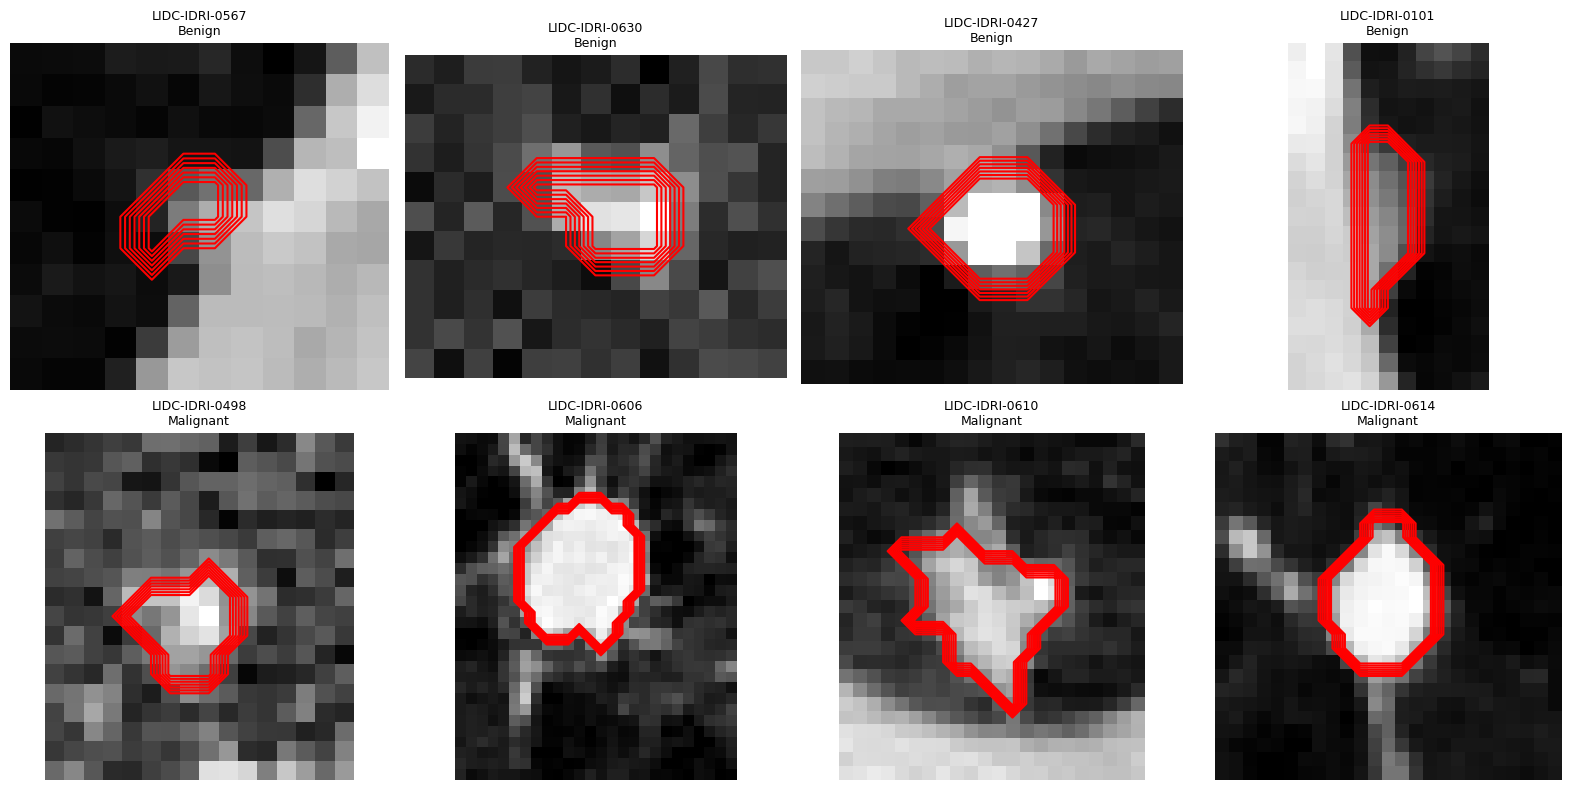

In [ ]:
# ROI Test

random.seed(7)  # different seed just for visualization sample selection

N_SAMPLES_TO_VIEW = 8

valid_samples = [n for n in sampled_nodules]
benign_samples = [n for n in valid_samples if n["label"] == 0]
malignant_samples = [n for n in valid_samples if n["label"] == 1]

viz_samples = (
    random.sample(benign_samples, N_SAMPLES_TO_VIEW // 2) +
    random.sample(malignant_samples, N_SAMPLES_TO_VIEW // 2)
)

fig, axes = plt.subplots(2, N_SAMPLES_TO_VIEW // 2, figsize=(4 * (N_SAMPLES_TO_VIEW // 2), 8))
axes = axes.flatten()

for ax, nodule_info in zip(axes, viz_samples):
    pid = nodule_info["patient_id"]

    # read directly from the saved preprocessed files no DICOM access needed
    resampled_vol = np.load(f"{PREP_DIR}/{pid}_resampled_clamped_c23.npy")
    mask = np.load(f"{PREP_DIR}/{pid}_mask_c23.npy")

    slice_areas = mask.sum(axis=(0, 1))
    display_idx = int(np.argmax(slice_areas))

    ct_slice = resampled_vol[:, :, display_idx]
    mask_slice = mask[:, :, display_idx]

    ax.imshow(ct_slice, cmap="gray")
    ax.contour(mask_slice, colors="red", linewidths=1.5)
    label_str = "Malignant" if nodule_info["label"] == 1 else "Benign"
    ax.set_title(f"{pid}\n{label_str}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False

# Load pretrained weights
WEIGHTS = models.ResNet50_Weights.IMAGENET1K_V2 # ImageNet-pretrained ResNet-50 weights (torchvision)
weights_transforms = WEIGHTS.transforms()
IMAGENET_MEAN = torch.tensor(weights_transforms.mean).view(3, 1, 1)
IMAGENET_STD  = torch.tensor(weights_transforms.std).view(3, 1, 1)

MIN_SLICE_AREA_PX = 50   # minimum ROI area per slice (Demircioglu, 2023)

y_master  = np.array([{n["patient_id"]: n["label"] for n in sampled_nodules}[p] for p in master_pids])
pid_label = dict(zip(master_pids, y_master))

def preprocess_slice(sl_2d):
    sl = (sl_2d - sl_2d.min()) / (sl_2d.max() - sl_2d.min() + 1e-6)  # min-max to [0,1], the range ImageNet normalisation expects
    sl_t = torch.tensor(sl).unsqueeze(0).unsqueeze(0).float()
    sl_r = F.interpolate(sl_t, size=(224, 224), mode="bilinear", align_corners=False).squeeze(0)  # resize to 224 x 224 (He et al., 2016)
    sl_3ch = sl_r.repeat(3, 1, 1)                                                          # channel duplication (Brocki & Chung, 2023)
    return (sl_3ch - IMAGENET_MEAN) / IMAGENET_STD                                         # ImageNet mean/std normalisation (Demircioglu, 2023)

def select_valid_slices(mask): # slices with ROI >= 50 px (Demircioglu, 2023)
    slice_areas = mask.sum(axis=(0, 1)) # axial slices
    valid_idx = np.where(slice_areas >= MIN_SLICE_AREA_PX)[0]
    if len(valid_idx) == 0: # fallback: largest slice
        valid_idx = np.array([int(np.argmax(slice_areas))])
    return valid_idx

def extract_vector(vol, mask, net, batch_size=32):
    # 2048-d penultimate features per slice, max-pooled into one vector per nodule (Demircioglu, 2023)
    idx = select_valid_slices(mask)
    x = torch.stack([preprocess_slice(vol[:, :, s]) for s in idx])
    with torch.no_grad():
        f = np.concatenate([net(x[b:b + batch_size].to(device)).cpu().numpy()
                            for b in range(0, len(x), batch_size)])
    return f.max(axis=0)

def zscore_reduce(X_tr, X_te, y_tr, seed=42): # fitted on training fold only, applied unchanged to test fold
    sc = StandardScaler().fit(X_tr)
    return sc.transform(X_tr), sc.transform(X_te)

def pca_reduce(X_tr, X_te, y_tr, seed=42):            # deep features, C1 and C2 (Zheng et al., 2026)
    Z_tr, Z_te = zscore_reduce(X_tr, X_te, y_tr)
    pca = PCA(n_components=20, random_state=seed).fit(Z_tr)
    return pca.transform(Z_tr), pca.transform(Z_te)

def lasso_reduce(X_tr, X_te, y_tr, seed=42):          # radiomic features, C3 and C4 (Brocki & Chung, 2023); default C = 1 as in Demircioglu (2023)
    Z_tr, Z_te = zscore_reduce(X_tr, X_te, y_tr)
    sel = SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", random_state=42)).fit(Z_tr, y_tr)
    return sel.transform(Z_tr), sel.transform(Z_te)

def split_folds(X):                                   # fold-independent features (C1, C3)
    return [(X[tr], X[te]) for tr, te in fold_splits]

def cv_predict(fold_data, y, reduce, seed=42): # random forest, 100 trees (scikit-learn default), fitted per training fold; pooled out-of-fold predictions
    probs = np.zeros(len(y))
    for (tr, te), (X_tr, X_te) in zip(fold_splits, fold_data):
        Z_tr, Z_te = reduce(X_tr, X_te, y[tr], seed)
        rf = RandomForestClassifier(n_estimators=100, random_state=seed).fit(Z_tr, y[tr])
        probs[te] = rf.predict_proba(Z_te)[:, 1]
    return probs

def cached(stem, compute, y): # loads saved predictions if present, otherwise computes and saves them
    t, p = f"{stem}_true.npy", f"{stem}_probs.npy"
    if os.path.exists(t) and os.path.exists(p) and len(np.unique(np.load(t))) == 2:
        return np.load(p)
    probs = compute()
    np.save(t, y.astype(float)); np.save(p, probs)
    return probs

def report(name, probs, y=y_master): # metrics at the default 0.5 threshold; AUC from probabilities
    pred = (probs >= 0.5).astype(int)
    print(f"{name} | Acc {accuracy_score(y, pred):.3f} | Sens {recall_score(y, pred):.3f} | "
          f"Spec {recall_score(y, pred, pos_label=0):.3f} | Prec {precision_score(y, pred):.3f} | "
          f"AUC {roc_auc_score(y, probs):.3f}")

In [ ]:
# CONDITION 1
os.makedirs(RESULTS_DIR, exist_ok=True)

frozen_model = models.resnet50(weights=WEIGHTS)   # frozen ImageNet extractor
frozen_model.fc = nn.Identity() # output 2048-d penultimate features
frozen_model = frozen_model.to(device).eval()

native_mask = {n["patient_id"]: n["mask"] for n in sampled_nodules}  # masks at native resolution

def compute_c1():
    X = np.stack([extract_vector(np.load(f"{PREP_DIR}/{pid}_raw_c1.npy"), native_mask[pid], frozen_model)
                  for pid in master_pids])
    return cv_predict(split_folds(X), y_master, pca_reduce)   # z-score -> PCA (20) -> random forest

c1_probs = cached(f"{RESULTS_DIR}/c1", compute_c1, y_master)
c1_true, c1_preds = y_master, (c1_probs >= 0.5).astype(int)
report("C1 Frozen DL", c1_probs)

n_slices = [len(select_valid_slices(native_mask[pid])) for pid in master_pids]
print(f"Slices per patient: mean {np.mean(n_slices):.1f}, min {min(n_slices)}, max {max(n_slices)}, "
      f"single-slice {sum(n == 1 for n in n_slices)}/{len(n_slices)}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 180MB/s]


C1 Frozen DL | Acc 0.880 | Sens 0.870 | Spec 0.890 | Prec 0.888 | AUC 0.927
Slices per patient: mean 4.8, min 1, max 42, single-slice 164/400


In [ ]:
# CONDITION 2
C2_STEM, C2_FEATS_PATH = f"{RESULTS_DIR}/c2_seeded", f"{RESULTS_DIR}/c2_seeded_fold_features.pkl"
MAX_EPOCHS, PATIENCE = 20, 4

def c2_volume(pid):  # resampled 1 mm, clamped volume and resampled mask
    return np.load(f"{PREP_DIR}/{pid}_resampled_clamped_c23.npy"), np.load(f"{PREP_DIR}/{pid}_mask_c23.npy")

def pooled_logit(pid, net):
    # per-slice logits max-pooled into one nodule-level prediction
    vol, mask = c2_volume(pid)
    x = torch.stack([preprocess_slice(vol[:, :, s]) for s in select_valid_slices(mask)]).to(device)
    return net(x).max(dim=0).values

def train_fold_model(train_idx):
    train_pids = [master_pids[i] for i in train_idx]
    # 10% stratified inner validation split; the outer test fold is never used here
    inner_pids, val_pids = train_test_split(train_pids, test_size=0.1, stratify=y_master[train_idx], random_state=42)
    label = lambda pid: torch.tensor([pid_label[pid]], dtype=torch.float32).to(device)

    net = models.resnet50(weights=WEIGHTS)
    for p in net.parameters():
        p.requires_grad = False
    for p in net.layer4.parameters(): # only layer 4 updates (Tajbakhsh et al., 2016)
        p.requires_grad = True
    net.fc = nn.Linear(net.fc.in_features, 1)   # single-logit head for binary task (Tajbakhsh et al., 2016)
    net = net.to(device)
    opt = torch.optim.Adam([p for p in net.parameters() if p.requires_grad], lr=1e-4) # Adam (Brocki & Chung, 2023); low LR set in advance
    loss_fn = nn.BCEWithLogitsLoss()

    best, best_state, wait = float("inf"), None, 0
    for epoch in range(MAX_EPOCHS):
        net.train()
        for i in np.random.permutation(len(inner_pids)):            # one patient per optimiser step
            opt.zero_grad()
            loss_fn(pooled_logit(inner_pids[i], net), label(inner_pids[i])).backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            val = sum(loss_fn(pooled_logit(pid, net), label(pid)).item() for pid in val_pids) / len(val_pids)
        if val < best:
            best, best_state, wait = val, copy.deepcopy(net.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE:                                     # stop after 4 epochs without improvement; best weights restored below
                break
    net.load_state_dict(best_state)
    net.fc = nn.Identity()                                           # head discarded: features go to the shared random forest (Astaraki et al., 2021)
    return net.eval()

if os.path.exists(f"{C2_STEM}_probs.npy") and os.path.exists(C2_FEATS_PATH):
    fold_features = pickle.load(open(C2_FEATS_PATH, "rb"))           # load saved per-fold deep features
    c2_probs = np.load(f"{C2_STEM}_probs.npy")
else:
    random.seed(42); np.random.seed(42); torch.manual_seed(42); torch.cuda.manual_seed_all(42) # fixed random seeds
    torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False # deterministic settings
    fold_features = []
    for k, (tr, te) in enumerate(fold_splits):
        net = train_fold_model(tr)
        fold_features.append(tuple(np.stack([extract_vector(*c2_volume(master_pids[i]), net) for i in idx])
                                   for idx in (tr, te)))
        print(f"Fold {k + 1} done")
    pickle.dump(fold_features, open(C2_FEATS_PATH, "wb"))
    c2_probs = cv_predict(fold_features, y_master, pca_reduce)
    np.save(f"{C2_STEM}_true.npy", y_master.astype(float)); np.save(f"{C2_STEM}_probs.npy", c2_probs)

c2_true, c2_preds = y_master, (c2_probs >= 0.5).astype(int)
report("C2 Fine-tuned DL", c2_probs)

Fold 1 done
Fold 2 done
Fold 3 done
Fold 4 done
Fold 5 done
Fold 6 done
Fold 7 done
Fold 8 done
Fold 9 done
Fold 10 done
C2 Fine-tuned DL | Acc 0.823 | Sens 0.825 | Spec 0.820 | Prec 0.821 | AUC 0.904


In [ ]:
# CONDITION 3: PyRadiomics on resampled and clamped volumes
os.makedirs(RESULTS_DIR, exist_ok=True)
RAD_FEATS_PATH = f"{RESULTS_DIR}/radiomics_features.pkl"

def extract_radiomics_df():
     # 25 HU fixed bin width (Demircioglu, 2023)
    extractor = featureextractor.RadiomicsFeatureExtractor(binWidth=25, resampledPixelSpacing=None, interpolator="sitkBSpline",
                                                           normalize=False, removeOutliers=None, label=1)
    # no resampling or normalisation, as both were applied in preprocessing
    extractor.disableAllFeatures()
    for feature_class in ("firstorder", "glcm", "glrlm", "shape"): # 72 features (Tang et al., 2024)
        extractor.enableFeatureClassByName(feature_class)
    radiomics_dataset = []
    for pid in master_pids:                                            # rows in master_pids order
        image_sitk = sitk.GetImageFromArray(np.load(f"{PREP_DIR}/{pid}_resampled_clamped_c23.npy"))
        mask_sitk  = sitk.GetImageFromArray(np.load(f"{PREP_DIR}/{pid}_mask_c23.npy").astype(np.uint8))
        features = {k: v for k, v in extractor.execute(image_sitk, mask_sitk).items() if not k.startswith("diagnostics")}
        radiomics_dataset.append({**features, "patient_id": pid, "label": pid_label[pid]})
    return pd.DataFrame(radiomics_dataset)

if not os.path.exists(RAD_FEATS_PATH):
    extract_radiomics_df().to_pickle(RAD_FEATS_PATH)
radiomics_df = pd.read_pickle(RAD_FEATS_PATH)
assert list(radiomics_df["patient_id"]) == list(master_pids)
feature_cols = [c for c in radiomics_df.columns if c not in ("patient_id", "label")]
X_rad = radiomics_df[feature_cols].values.astype(float)

c3_probs = cached(f"{RESULTS_DIR}/c3", lambda: cv_predict(split_folds(X_rad), y_master, lasso_reduce), y_master) # z-score -> LASSO -> RF
c3_true, c3_preds = y_master, (c3_probs >= 0.5).astype(int)
report("C3 Radiomics", c3_probs)

n_sel = [lasso_reduce(X_rad[tr], X_rad[te], y_master[tr])[0].shape[1] for tr, te in fold_splits] # LASSO-selected features per fold

C3 Radiomics | Acc 0.848 | Sens 0.830 | Spec 0.865 | Prec 0.860 | AUC 0.905


In [ ]:
# CONDITION 4
def fusion_reduce(X_tr, X_te, y_tr, seed=42):
    (r_tr, d_tr), (r_te, d_te) = X_tr, X_te
    rr = lasso_reduce(r_tr, r_te, y_tr)                # Z-score Normalisation + LASSO Feature Selection (radiomics)
    dd = zscore_reduce(d_tr, d_te, y_tr)               # Z-score Normalisation (deep features)
    return np.hstack([rr[0], dd[0]]), np.hstack([rr[1], dd[1]])   # Feature Fusion (radiomics first, then deep)

# Radiomics features from Condition 3 (X_rad) and Deep Features from Condition 2 (fold_features), per fold
fusion_folds = [((X_rad[tr], feat_train_dl), (X_rad[te], feat_test_dl))
                for (tr, te), (feat_train_dl, feat_test_dl) in zip(fold_splits, fold_features)]

# Cross Validation with Random Forest Classifier; Save Results, or Load Results if already computed
c4_probs = cached(f"{RESULTS_DIR}/c4_seeded", lambda: cv_predict(fusion_folds, y_master, fusion_reduce), y_master)
c4_true, c4_preds = y_master, (c4_probs >= 0.5).astype(int)

# Final Performance
report("C4 Fusion", c4_probs)

C4 Fusion | Acc 0.835 | Sens 0.800 | Spec 0.870 | Prec 0.860 | AUC 0.904


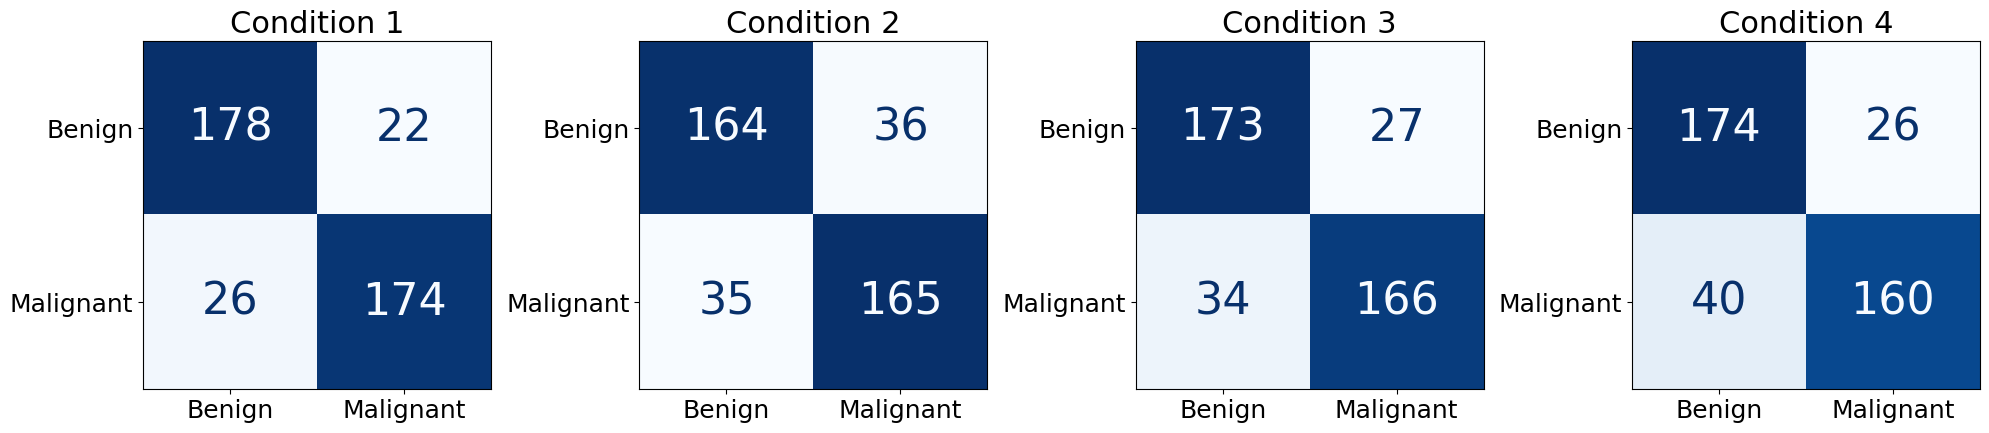

Condition 1:
[[178  22]
 [ 26 174]]

Condition 2:
[[164  36]
 [ 35 165]]

Condition 3:
[[173  27]
 [ 34 166]]

Condition 4:
[[174  26]
 [ 40 160]]



In [ ]:
#Confusion Matrix

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

conditions = [
    ("Condition 1", c1_true, c1_preds),
    ("Condition 2", c2_true, c2_preds),
    ("Condition 3", c3_true, c3_preds),
    ("Condition 4", c4_true, c4_preds)
]

cms = []

for ax, (title, y_true, y_pred) in zip(axes.ravel(), conditions):

    cm = confusion_matrix(y_true, y_pred)
    cms.append((title, cm))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False, text_kw={"fontsize": 32})
    ax.set_title(title, fontsize=22)
    ax.tick_params(labelsize=18)
    ax.set_xlabel('')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

for title, cm in cms:
    print(f"{title}:\n{cm}\n")

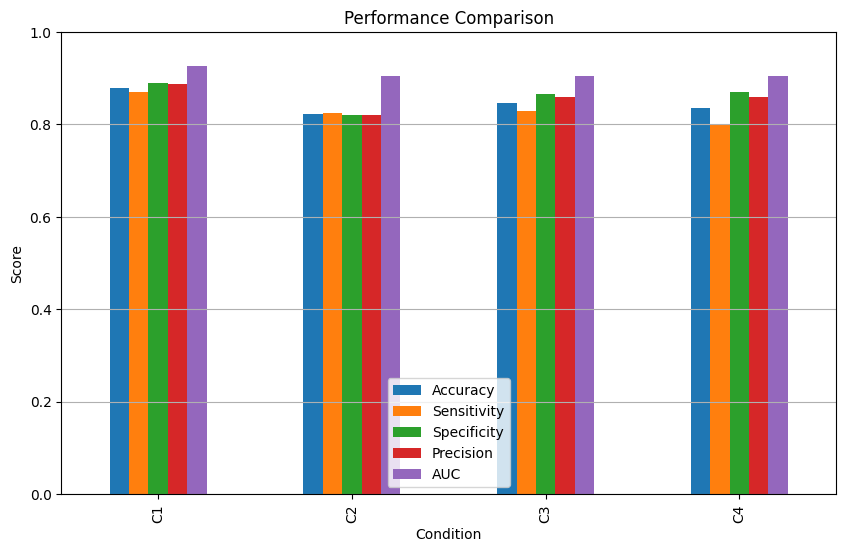

In [ ]:
#Bar Chart


metrics = pd.DataFrame({

    "Condition":[
        "C1",
        "C2",
        "C3",
        "C4"
    ],

    "Accuracy":[
        accuracy_score(c1_true,c1_preds),
        accuracy_score(c2_true,c2_preds),
        accuracy_score(c3_true,c3_preds),
        accuracy_score(c4_true,c4_preds)
    ],

    "Sensitivity":[
        recall_score(c1_true,c1_preds),
        recall_score(c2_true,c2_preds),
        recall_score(c3_true,c3_preds),
        recall_score(c4_true,c4_preds)
    ],

    "Specificity":[
        recall_score(c1_true,c1_preds,pos_label=0),
        recall_score(c2_true,c2_preds,pos_label=0),
        recall_score(c3_true,c3_preds,pos_label=0),
        recall_score(c4_true,c4_preds,pos_label=0)
    ],

    "Precision":[
        precision_score(c1_true,c1_preds),
        precision_score(c2_true,c2_preds),
        precision_score(c3_true,c3_preds),
        precision_score(c4_true,c4_preds)
    ],

    "AUC":[
        roc_auc_score(c1_true,c1_probs),
        roc_auc_score(c2_true,c2_probs),
        roc_auc_score(c3_true,c3_probs),
        roc_auc_score(c4_true,c4_probs)
    ]

})

metrics.set_index("Condition").plot(
    kind="bar",
    figsize=(10,6)
)

plt.ylim(0,1)

plt.ylabel("Score")

plt.title("Performance Comparison")

plt.grid(axis="y")

plt.show()

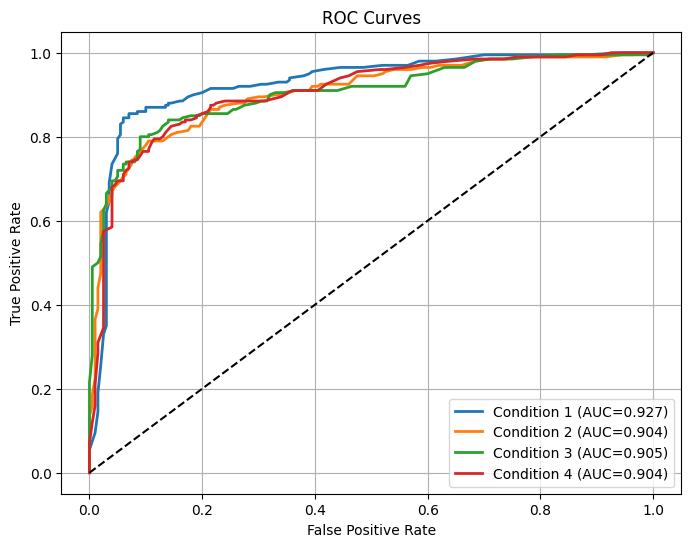

In [ ]:
#ROC Curve

plt.figure(figsize=(8,6))

conditions = [
    ("Condition 1", c1_true, c1_probs),
    ("Condition 2", c2_true, c2_probs),
    ("Condition 3", c3_true, c3_probs),
    ("Condition 4", c4_true, c4_probs)
]

for name, y_true, y_prob in conditions:

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = sk_auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC={roc_auc:.3f})"
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend(loc="lower right")

plt.grid(True)

plt.show()

In [ ]:
# DeLong's test for correlated ROC curves (DeLong et al., 1988; fast algorithm of Sun & Xu, 2014), via MLstatkit
def delong_roc_test(true_labels, probs_a, probs_b):
    z, p, _, _, auc_a, auc_b, info = Delong_test(true_labels, probs_a, probs_b)
    assert info["method"] == "delong", "MLstatkit fell back to bootstrap"
    return auc_a, auc_b, abs(z), p

# run pairwise DeLong tests across all four conditions
cond_probs = {"C1": c1_probs, "C2": c2_probs, "C3": c3_probs, "C4": c4_probs}

rows = []
for a, b in combinations(cond_probs, 2):
    auc_a, auc_b, z, p = delong_roc_test(y_master, cond_probs[a], cond_probs[b])
    rows.append({"Comparison": f"{a} vs {b}", "AUC A": f"{auc_a:.3f}", "AUC B": f"{auc_b:.3f}",
                 "ΔAUC": f"{auc_a - auc_b:+.3f}", "z": f"{z:.3f}", "p-value": f"{p:.4f}"})
print(pd.DataFrame(rows).to_string(index=False))

Comparison AUC A AUC B   ΔAUC     z p-value
  C1 vs C2 0.927 0.904 +0.023 1.751  0.0799
  C1 vs C3 0.927 0.905 +0.022 1.674  0.0942
  C1 vs C4 0.927 0.904 +0.023 1.893  0.0584
  C2 vs C3 0.904 0.905 -0.001 0.046  0.9635
  C2 vs C4 0.904 0.904 -0.000 0.005  0.9957
  C3 vs C4 0.905 0.904 +0.001 0.046  0.9630


In [ ]:
# shuffle preprocessing

def zoom_factors(scan):  # native spacing -> 1 mm isotropic (same factors as cell 15)
    return (scan.pixel_spacing / TARGET_SPACING, scan.pixel_spacing / TARGET_SPACING,
            scan.slice_thickness / TARGET_SPACING)

def variants_complete(pid):  # true if the patient already has both extra variant files
    return all(os.path.exists(f"{PREP_DIR}/{pid}{s}") for s in ("_raw_clamped_c1.npy", "_resampled_c1.npy"))

pid_to_scan = {n["patient_id"]: n["scan"] for n in sampled_nodules}
for pid in [p for p in master_pids if not variants_complete(p)]:
    raw = np.load(f"{PREP_DIR}/{pid}_raw_c1.npy")
    np.save(f"{PREP_DIR}/{pid}_raw_clamped_c1.npy", hu_clamp(raw).astype(np.float32))
    np.save(f"{PREP_DIR}/{pid}_resampled_c1.npy", zoom(raw, zoom_factors(pid_to_scan[pid]), order=3, output=np.float32))
print("All preprocessing variants present:", all(variants_complete(p) for p in master_pids))

All preprocessing variants present: True


In [ ]:
# preprocessing comparison
os.makedirs(COMPARISON_DIR, exist_ok=True)
VARIANTS = {"raw_no_clamp":       ("_raw_c1.npy",                "native"),
            "raw_clamp":          ("_raw_clamped_c1.npy",        "native"),
            "resampled_no_clamp": ("_resampled_c1.npy",          "resampled"),
            "resampled_clamp":    ("_resampled_clamped_c23.npy", "resampled")}

def variant_mask(pid, kind):
    return native_mask[pid] if kind == "native" else np.load(f"{PREP_DIR}/{pid}_mask_c23.npy")

variant_features = {}
for name, (suffix, kind) in VARIANTS.items():
    path = f"{COMPARISON_DIR}/{name}_features.npy"
    if not os.path.exists(path):
        np.save(path, np.stack([extract_vector(np.load(f"{PREP_DIR}/{pid}{suffix}"), variant_mask(pid, kind), frozen_model)
                                for pid in master_pids]))
    X = variant_features[name] = np.load(path)
    probs = cached(f"{COMPARISON_DIR}/{name}", lambda: cv_predict(split_folds(X), y_master, pca_reduce), y_master)
    print(f"{name}: AUC = {roc_auc_score(y_master, probs):.3f}")

raw_no_clamp: AUC = 0.927
raw_clamp: AUC = 0.922
resampled_no_clamp: AUC = 0.903
resampled_clamp: AUC = 0.901


In [ ]:
# 10 seed check
SEED_RESULTS_PATH = f"{COMPARISON_DIR}/ten_seed_results.pkl"
if os.path.exists(SEED_RESULTS_PATH):
    seed_results = pickle.load(open(SEED_RESULTS_PATH, "rb"))
else:
    seed_results = {name: [roc_auc_score(y_master, cv_predict(split_folds(X), y_master, pca_reduce, seed))
                           for seed in range(1, 11)]
                    for name, X in variant_features.items()}
    pickle.dump(seed_results, open(SEED_RESULTS_PATH, "wb"))

for name, aucs in seed_results.items():
    print(f"{name}: mean={np.mean(aucs):.3f} ± {np.std(aucs):.3f} (range {min(aucs):.3f}-{max(aucs):.3f})")

raw_no_clamp: mean=0.930 ± 0.002 (range 0.927-0.932)
raw_clamp: mean=0.924 ± 0.003 (range 0.919-0.929)
resampled_no_clamp: mean=0.903 ± 0.003 (range 0.899-0.908)
resampled_clamp: mean=0.897 ± 0.003 (range 0.894-0.903)


In [ ]:
# DeLong for preprocessing configs
var_probs = {name: np.load(f"{COMPARISON_DIR}/{name}_probs.npy") for name in VARIANTS}
ref = var_probs["raw_no_clamp"]
for name in ["raw_clamp", "resampled_no_clamp", "resampled_clamp"]:
    a, b, _, p = delong_roc_test(y_master.astype(float), ref, var_probs[name])
    print(f"raw_no_clamp ({a:.3f}) vs {name} ({b:.3f}): ΔAUC = {b - a:+.3f}, p = {p:.4f}")

a, b, _, p = delong_roc_test(y_master.astype(float), var_probs["resampled_no_clamp"], var_probs["resampled_clamp"])
print(f"resampled: no clamp ({a:.3f}) vs clamp ({b:.3f}): p = {p:.4f}")

a, b, _, p = delong_roc_test(y_master.astype(float), var_probs["resampled_clamp"], c2_probs)
print(f"matched preprocessing: frozen ({a:.3f}) vs fine-tuned ({b:.3f}): ΔAUC = {b - a:+.3f}, p = {p:.4f}")

print(f"Radiomic features per nodule: {len(feature_cols)}")

raw_no_clamp (0.927) vs raw_clamp (0.922): ΔAUC = -0.005, p = 0.3712
raw_no_clamp (0.927) vs resampled_no_clamp (0.903): ΔAUC = -0.024, p = 0.0357
raw_no_clamp (0.927) vs resampled_clamp (0.901): ΔAUC = -0.026, p = 0.0233
resampled: no clamp (0.903) vs clamp (0.901): p = 0.7567
matched preprocessing: frozen (0.901) vs fine-tuned (0.904): ΔAUC = +0.003, p = 0.7933
Radiomic features per nodule: 72


In [ ]:
def matched_fusion_reduce(X_tr, X_te, y_tr, seed=42):   # deep branch reduced to 20 PCs (Mei et al., 2023)
    (r_tr, d_tr), (r_te, d_te) = X_tr, X_te
    rr, dd = lasso_reduce(r_tr, r_te, y_tr), pca_reduce(d_tr, d_te, y_tr, seed)
    return np.hstack([rr[0], dd[0]]), np.hstack([rr[1], dd[1]])

c4m_probs = cached(f"{RESULTS_DIR}/c4_matched_seeded",
                   lambda: cv_predict(fusion_folds, y_master, matched_fusion_reduce), y_master)
report("Matched fusion", c4m_probs)
for name, probs in [("Fine-tuned DL", c2_probs), ("Radiomics", c3_probs), ("Original fusion", c4_probs)]:
    a, b, _, p = delong_roc_test(y_master.astype(float), c4m_probs, probs)
    print(f"  vs {name}: {a:.3f} vs {b:.3f}, p = {p:.4f}")

Matched fusion | Acc 0.855 | Sens 0.825 | Spec 0.885 | Prec 0.878 | AUC 0.916
  vs Fine-tuned DL: 0.916 vs 0.904, p = 0.2329
  vs Radiomics: 0.916 vs 0.905, p = 0.1268
  vs Original fusion: 0.916 vs 0.904, p = 0.2853


In [ ]:
# section 4.4 radiomic size ablation test
# explicit size measures; ratio descriptors (Elongation, Flatness, Sphericity) are scale-invariant and kept
SIZE_TERMS = ["LeastAxisLength", "MajorAxisLength", "MinorAxisLength", "Maximum2DDiameterSlice",
              "Maximum2DDiameterRow", "Maximum2DDiameterColumn", "Maximum3DDiameter",
              "MeshVolume", "VoxelVolume", "SurfaceArea"]
size_cols  = [c for c in feature_cols if any(t in c for t in SIZE_TERMS)]
shape_cols = [c for c in feature_cols if c.startswith("original_shape_")]
subsets = {"full":     feature_cols,
           "no_size":  [c for c in feature_cols if c not in size_cols],
           "no_shape": [c for c in feature_cols if c not in shape_cols]}
print(f"Removed {len(size_cols)} size features and {len(shape_cols)} shape features")

# run Condition 3's pipeline on each subset
abl = {name: cv_predict(split_folds(radiomics_df[cols].values.astype(float)), y_master, lasso_reduce)
       for name, cols in subsets.items()}

# DeLong: each reduced set against the full set
for name in ["no_size", "no_shape"]:
    a, b, _, p = delong_roc_test(y_master.astype(float), abl["full"], abl[name])
    print(f"full ({a:.3f}) vs {name} ({b:.3f}): ΔAUC = {abs(a - b):.3f}, p = {p:.4f}")

Removed 10 size features and 14 shape features
full (0.905) vs no_size (0.902): ΔAUC = 0.003, p = 0.5680
full (0.905) vs no_shape (0.907): ΔAUC = 0.002, p = 0.6554


In [ ]:
# Selected LASSO features
_X3 = pd.read_pickle(f"{RESULTS_DIR}/radiomics_features.pkl").drop(columns=["patient_id", "label"]).values.astype(float)
_y3 = np.array([{n["patient_id"]: n["label"] for n in sampled_nodules}[p] for p in master_pids])
n_sel = [SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", random_state=42))
         .fit(StandardScaler().fit_transform(_X3[tr]), _y3[tr]).get_support().sum() for tr, _ in fold_splits]
print(f"LASSO-selected radiomic features per fold: {n_sel} \n(range {min(n_sel)}-{max(n_sel)})")

LASSO-selected radiomic features per fold: [np.int64(26), np.int64(24), np.int64(22), np.int64(25), np.int64(22), np.int64(22), np.int64(22), np.int64(20), np.int64(24), np.int64(24)] 
(range 20-26)


In [ ]:
# error overlaps

res = {}
for c in ["c1","c2_seeded","c3","c4_seeded"]:
    t = np.load(f"{RESULTS_DIR}/{c}_true.npy")
    p = np.load(f"{RESULTS_DIR}/{c}_probs.npy")
    res[c] = (p >= 0.5).astype(int) != t.astype(int)   # error mask

for a, b in itertools.combinations(res, 2):
    both = (res[a] & res[b]).sum()
    either = (res[a] | res[b]).sum()
    print(f"{a} vs {b}: both wrong {both}, either wrong {either}, overlap {both/either:.1%}")

print("wrong in all four:", np.logical_and.reduce(list(res.values())).sum())
print("wrong in none:", (~np.logical_or.reduce(list(res.values()))).sum())

c1 vs c2_seeded: both wrong 31, either wrong 88, overlap 35.2%
c1 vs c3: both wrong 35, either wrong 74, overlap 47.3%
c1 vs c4_seeded: both wrong 36, either wrong 78, overlap 46.2%
c2_seeded vs c3: both wrong 36, either wrong 96, overlap 37.5%
c2_seeded vs c4_seeded: both wrong 50, either wrong 87, overlap 57.5%
c3 vs c4_seeded: both wrong 41, either wrong 86, overlap 47.7%
wrong in all four: 22
wrong in none: 291


In [ ]:
# 95% bootstrap CIs: paired stratified resampling of the 400 pooled out-of-fold predictions, 2000 resamples, seed 42
def paired_bootstrap_aucs(y, probs, B=2000, seed=42):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    idx = [np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(B)]  # same nodules for every condition
    return {name: np.array([roc_auc_score(y[i], p[i]) for i in idx]) for name, p in probs.items()}

probs = {"C1": c1_probs, "C2": c2_probs, "C3": c3_probs, "C4": c4_probs}
boot  = paired_bootstrap_aucs(y_master, probs)

rows = []
for a, b in combinations(probs, 2):
    lo, hi = np.quantile(boot[a] - boot[b], [0.025, 0.975])
    rows.append({"Comparison": f"{a} vs {b}",
                 "ΔAUC": f"{roc_auc_score(y_master, probs[a]) - roc_auc_score(y_master, probs[b]):+.3f}",
                 "95% CI": f"[{lo:+.4f}, {hi:+.4f}]",
                 "Half-width": f"{(hi - lo) / 2:.3f}",
                 "Contains 0": lo <= 0 <= hi})
print(pd.DataFrame(rows).to_string(index=False))

Comparison   ΔAUC             95% CI Half-width  Contains 0
  C1 vs C2 +0.023 [-0.0026, +0.0480]      0.025        True
  C1 vs C3 +0.022 [-0.0047, +0.0505]      0.028        True
  C1 vs C4 +0.023 [-0.0001, +0.0471]      0.024        True
  C2 vs C3 -0.001 [-0.0257, +0.0247]      0.025        True
  C2 vs C4 -0.000 [-0.0179, +0.0184]      0.018        True
  C3 vs C4 +0.001 [-0.0219, +0.0229]      0.022        True


C1 - Frozen DL: PC1 28.7%, PC2 4.6%
C2 - Fine-tuned DL: PC1 32.7%, PC2 3.7%
C3 - Radiomics: PC1 34.6%, PC2 23.9%
C4 - Fusion: PC1 32.1%, PC2 3.6%


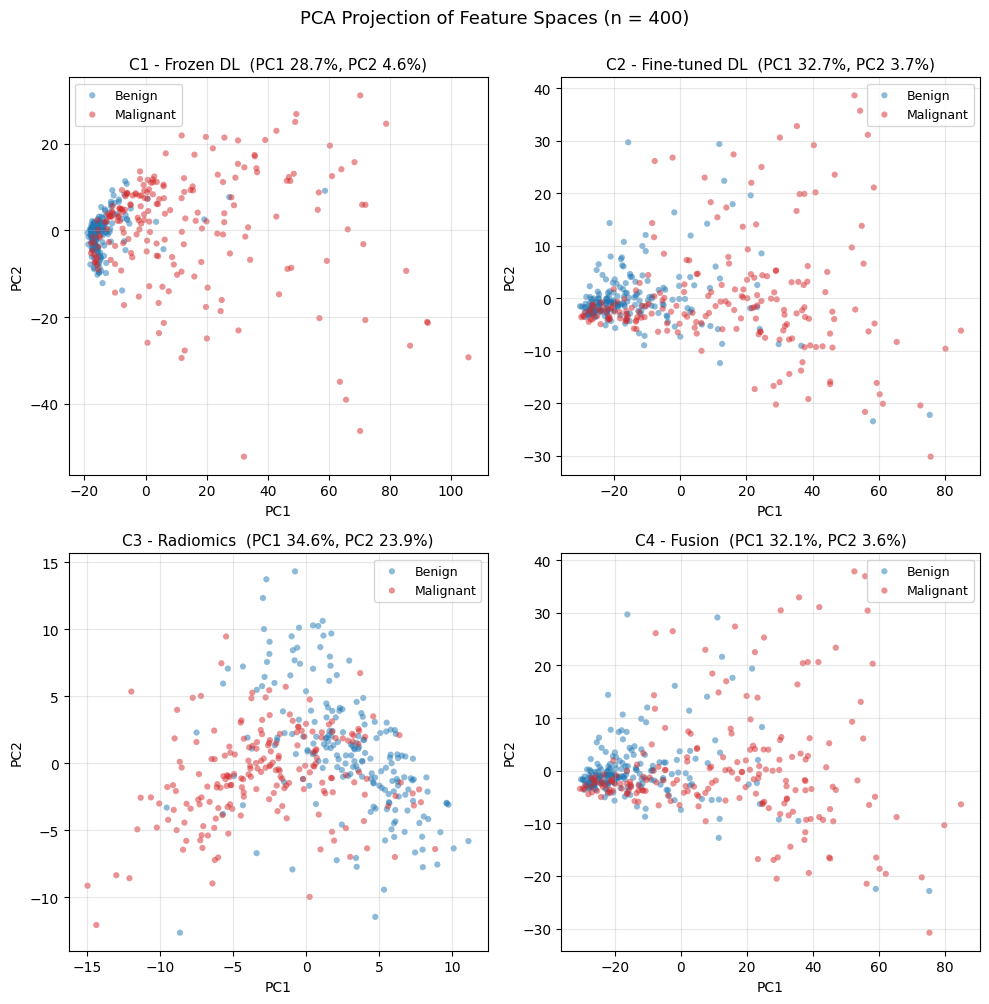

Saved: /content/drive/MyDrive/LIDC-IDRI COLAB/results/fig4_feature_space.png


In [ ]:
# PCA Feature Space Visualization
COMP_DIR    = os.path.join(RESULTS_DIR, "hu_clamp_resampling_comparison")
OUT_PATH    = os.path.join(RESULTS_DIR, "fig4_feature_space.png")

# Load features
X_c1 = np.load(os.path.join(COMP_DIR, "raw_no_clamp_features.npy"))

with open(os.path.join(RESULTS_DIR, "radiomics_features.pkl"), "rb") as f:
    c3_df = pickle.load(f)
feature_cols = [c for c in c3_df.columns if c not in ("patient_id", "label")]
X_c3 = c3_df[feature_cols].values.astype(np.float64)
y    = c3_df["label"].astype(int).values

# Align C2 rows to the master patient order (since folds are shuffled)
fold_data   = pickle.load(open(f"{BASE}/fold_splits.pkl", "rb"))
pids_order  = fold_data["pids_order"]
fold_splits = fold_data["fold_splits"]
assert list(c3_df["patient_id"]) == list(pids_order)

with open(os.path.join(RESULTS_DIR, "c2_seeded_fold_features.pkl"), "rb") as f:
    c2_folds = pickle.load(f)
X_c2 = np.zeros((len(pids_order), c2_folds[0][1].shape[1]))
for (tr, te), (_, f_te) in zip(fold_splits, c2_folds):
    X_c2[te] = f_te

X_c4 = np.concatenate([X_c2, X_c3], axis=1)

# PCA + Plot
conditions = [
    ("C1 - Frozen DL",     X_c1),
    ("C2 - Fine-tuned DL", X_c2),
    ("C3 - Radiomics",     X_c3),
    ("C4 - Fusion",        X_c4),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, (name, X) in zip(axes.flatten(), conditions):
    X_scaled = StandardScaler().fit_transform(X)
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_scaled)
    ev = pca.explained_variance_ratio_
    print(f"{name}: PC1 {ev[0]:.1%}, PC2 {ev[1]:.1%}")

    ax.scatter(X_pca[y == 0, 0], X_pca[y == 0, 1], c="tab:blue",
               alpha=0.5, s=20, edgecolors="none", label="Benign")
    ax.scatter(X_pca[y == 1, 0], X_pca[y == 1, 1], c="tab:red",
               alpha=0.5, s=20, edgecolors="none", label="Malignant")
    ax.set_title(f"{name}  (PC1 {ev[0]:.1%}, PC2 {ev[1]:.1%})", fontsize=11)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(loc="best", fontsize=9)
    ax.grid(True, alpha=0.3)


plt.suptitle("PCA Projection of Feature Spaces (n = 400)", fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig(OUT_PATH, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {OUT_PATH}")

